# INF201 – Deliverable 3: A mini-RPG battle simulator

**Authors:** Mathias Gundersen & Jakub Mermer
**GitHub repository:** https://github.com/saltonese/Del_3-G6_5.git

In this notebook we present the classes that make up our battle simulator, and use them to simulate battles between different types of characters, with and without weapons. The reusable code lives in separate modules; the notebook is only used for presentation and experiments.

| Module | Classes | Purpose |
|---|---|---|
| `dice.py` | `Dice` | Randomness: an n-sided dice |
| `items.py` | `Weapon` | Items a character can hold; the damage is decided by a dice |
| `character.py` | `Character`, `Warrior`, `Mage` | The characters, with the specialisations as subclasses |
| `battle.py` | `Battle` | Turn-based combat between two characters |

How the classes relate to each other (an arrow means "is used by" or "is the parent of"):

```
Dice --> Weapon --> Character --> Warrior, Mage
                        |
                        v
                 Battle(hero, enemy)
```

- **Composition** : a `Weapon` has a `Dice`, and a `Character` has a `Weapon`.
- **Inheritance** : `Warrior` and `Mage` are specialised `Character`s.
- A `Battle` *uses* two `Character` objects, and works with any subclass thanks to the shared public interface (`attack()`, `is_alive`, `hp`, ...).

## Setup

All random behaviour goes through Python's `random` module, so we seed it to make the results reproducible. The helper `show_class()` prints an overview of a class (constructor, attributes, properties and methods) and marks what is inherited; we use it to present each class below.

In [30]:
import inspect
import random
from collections import Counter

import matplotlib.pyplot as plt
from pathlib import Path
import sys

project_dir = Path.cwd()
if not (project_dir / "Scripts").is_dir():
    project_dir = project_dir.parent

sys.path.insert(0, str(project_dir / "Scripts"))

In [31]:
from Task_5_Battles import Battle
from Task_1_4_Characters import Character, Mage, Warrior
from Task_2_Dice import Dice
from Task_3_items import Weapon

random.seed(42)  # reproducible results

In [32]:
def show_class(cls, instance=None) -> None:
    """Print an overview of a class: constructor, attributes, properties and methods."""
    # Collect everything defined in the class or in its parents (not `object`).
    # Parents first, so that a subclass overrides what it redefines.
    owners = {}
    for klass in reversed(cls.__mro__[:-1]):
        for name, member in vars(klass).items():
            owners[name] = (klass, member)

    def label(name: str) -> str:
        klass = owners[name][0]
        return name if klass is cls else f"{name}  (inherited from {klass.__name__})"

    def section(title: str, names: list) -> None:
        if names:
            print(f"  {title}:")
            for name in names:
                print(f"    - {label(name)}")

    bases = [base.__name__ for base in cls.__bases__ if base is not object]
    print(f"class {cls.__name__}" + (f"({', '.join(bases)})" if bases else ""))
    try:
        signature = inspect.signature(cls, eval_str=True)
    except Exception:  # fall back if a type hint cannot be evaluated
        signature = inspect.signature(cls)
    print(f"  constructor: {cls.__name__}{signature}")

    if instance is not None:
        print("  instance attributes (a leading _ means protected):")
        print("    " + ", ".join(vars(instance)))

    constants = [n for n in owners if n.isupper()]
    if constants:
        print("  class constants:")
        for name in constants:
            print(f"    - {name} = {owners[name][1]}")

    section("properties (read-only)", [n for n, (_, m) in owners.items() if isinstance(m, property)])
    section("methods", [n for n, (_, m) in owners.items() if inspect.isfunction(m) and not n.startswith("_")])
    section(
        "special methods",
        [n for n, (_, m) in owners.items() if inspect.isfunction(m) and n.startswith("__") and n != "__init__"],
    )

In [33]:
# Chart style: light surface, recessive hairline grid, text in ink colours.
# The two series colours (blue, orange) are the first two slots of a colour-blind-safe categorical palette.
SURFACE, INK, INK_2 = "#fcfcfb", "#0b0b0b", "#52514e"
GRID, BASELINE = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"


def style_axes(ax, grid_axis: str = "y") -> None:
    """Apply a clean, quiet chart style to a matplotlib axes."""
    ax.figure.set_facecolor(SURFACE)
    ax.set_facecolor(SURFACE)
    for side in ("top", "right", "left", "bottom"):
        ax.spines[side].set_visible(False)
    ax.grid(axis=grid_axis, color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    ax.tick_params(colors=INK_2, length=0)
    ax.xaxis.label.set_color(INK_2)
    ax.yaxis.label.set_color(INK_2)

## `Dice` (task 2)

`Dice` models an n-sided dice and is what introduces randomness into the game.

- The number of sides must be at least 2, otherwise a `ValueError` is raised.
- `sides` is stored in the protected attribute `_sides` and exposed through a read-only property, so the validation cannot be bypassed after the dice has been created.
- `roll()` returns `random.randint(1, sides)`. `__call__` lets us write `d20()` instead of `d20.roll()`, and `__repr__` gives strings like `Dice(sides=6)`.

In [34]:
d6 = Dice()            # default: 6 sides
d20 = Dice(sides=20)
show_class(Dice, d6)

class Dice
  constructor: Dice(sides: int = 6) -> None
  instance attributes (a leading _ means protected):
    _sides
  properties (read-only):
    - sides
  methods:
    - roll
  special methods:
    - __call__
    - __repr__


In [35]:
print(repr(d6), repr(d20))
print("d20.roll():", d20.roll())
print("d20():     ", d20())   # __call__ does the same as roll()

Dice(sides=6) Dice(sides=20)
d20.roll(): 4
d20():      1


In [36]:
# Invalid dice and the read-only property
try:
    Dice(sides=1)
except ValueError as error:
    print("ValueError:", error)

try:
    d6.sides = 100
except AttributeError as error:
    print("AttributeError:", error)

ValueError: A dice need at least 2 sides, got 1
AttributeError: property 'sides' of 'Dice' object has no setter


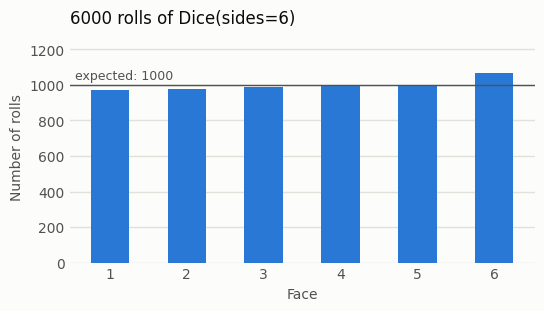

In [37]:
rolls = Counter(d6() for _ in range(6000))
faces = sorted(rolls)

fig, ax = plt.subplots(figsize=(6, 3))
style_axes(ax, grid_axis="y")
ax.bar(faces, [rolls[face] for face in faces], width=0.5, color=BLUE)
ax.axhline(1000, color=INK_2, linewidth=1)
ax.text(0.55, 1015, "expected: 1000", ha="left", va="bottom", color=INK_2, fontsize=9)
ax.set_ylim(0, 1300)
ax.set_xlabel("Face")
ax.set_ylabel("Number of rolls")
ax.set_title("6000 rolls of Dice(sides=6)", loc="left", color=INK)
plt.show()

## `Weapon` (task 3)

A `Weapon` has a `name` and a `damage_dice` (a `Dice`). This is **composition**: a weapon *has* a dice, and a character *has* a weapon. `roll_damage()` simply forwards to `damage_dice.roll()`, so the weapon decides *how* damage is rolled while the dice decides *what* is rolled.


In [38]:
sword = Weapon("Sword", Dice(sides=8))
show_class(Weapon, sword)

class Weapon
  constructor: Weapon(name: str, damage_dice: Task_2_Dice.Dice) -> None
  instance attributes (a leading _ means protected):
    name, damage_dice
  methods:
    - roll_damage
  special methods:
    - __repr__


In [39]:
print(repr(sword))
print("Ten damage rolls:" , [sword.roll_damage() for _ in range(10)])

Weapon(name='Sword', damage_dice=Dice(sides=8))
Ten damage rolls: [7, 7, 3, 2, 1, 4, 7, 3, 2, 3]


## `Character` (tasks 1 and 3)

`Character` is the extended version of the class from lecture 8. The main changes:

- **Encapsulation.** `_hp` is only changed by the character itself, through `take_damage()` and `heal()`. `attack()` no longer modifies `target._hp`; it asks the target to take damage instead. The public `hp` and `is_alive` are read-only properties.
- **HP stays between 0 and `hp_max`.** `take_damage()` stops at 0 and `heal()` stops at `hp_max`. Negative amounts raise a `ValueError`, and a dead character cannot be healed.
- **Weapons.** The constructor takes an optional `weapon`. A normal attack rolls the weapon's dice if there is one, and otherwise uses the base `damage`. This choice is made in the small helper `_roll_attack_damage()`, which subclasses can reuse.
- `take_damage()`, `heal()` and `attack()` return the number of HP that was actually lost or restored. This lets `Battle` log what happened using only public methods.

In [40]:
frodo = Character("Frodo", hp_max=100, damage=10)
show_class(Character, frodo)

class Character
  constructor: Character(name: str, hp_max: int = 100, damage: int = 10, weapon: Task_3_items.Weapon | None = None) -> None
  instance attributes (a leading _ means protected):
    name, _hp, hp_max, damage, weapon
  properties (read-only):
    - hp
    - is_alive
  methods:
    - take_damage
    - heal
    - attack
    - introduce
  special methods:
    - __repr__
    - __str__


In [41]:
print(frodo)         # __str__
print(repr(frodo))   # __repr__
frodo.introduce()

Character: Frodo with 100 HP and 10 damage
<Character name=Frodo hp=100 damage=10>
I am the mighty Frodo!


**Encapsulation in action.** The properties `hp` and `is_alive` cannot be assigned to from the outside:

In [43]:
for attribute in ("hp", "is_alive"):
    try:
        setattr(frodo, attribute, 50)
    except AttributeError as error:
        print(f"AttributeError when setting {attribute}: {error}")

AttributeError when setting hp: property 'hp' of 'Character' object has no setter
AttributeError when setting is_alive: property 'is_alive' of 'Character' object has no setter


**HP is always kept between 0 and `hp_max`:**

In [44]:
print("Start:   HP =", frodo.hp)
print("Lost", frodo.take_damage(30), "HP    -> HP =", frodo.hp)
print("Restored", frodo.heal(10), "HP -> HP =", frodo.hp)
print("Restored", frodo.heal(1000), "HP -> HP =", frodo.hp, f"(never above hp_max = {frodo.hp_max})")
print("Lost", frodo.take_damage(10_000), "HP -> HP =", frodo.hp, "| is_alive:", frodo.is_alive)
print("Restored", frodo.heal(50), "HP -> HP =", frodo.hp, "(a dead character cannot be healed)")

try:
    frodo.take_damage(-5)
except ValueError as error:
    print("ValueError:", error)

Start:   HP = 100
Lost 30 HP    -> HP = 70
Restored 10 HP -> HP = 80
Restored 20 HP -> HP = 100 (never above hp_max = 100)
Lost 100 HP -> HP = 0 | is_alive: False
Restored 0 HP -> HP = 0 (a dead character cannot be healed)
ValueError: Damage cannot be negative


**Attacking with and without a weapon.** An unarmed character always deals its base damage (10 here), while an armed character rolls the weapon's dice instead. The base damage is *not* added to the weapon roll.

In [45]:
dummy = Character("Training dummy", hp_max=10_000)
unarmed = Character("Unarmed", damage=10)
armed = Character("Armed", damage=10, weapon=Weapon("Sword", Dice(sides=8)))

print("Unarmed hits:", [unarmed.attack(dummy) for _ in range(8)])
print("Armed hits:  ", [armed.attack(dummy) for _ in range(8)])

Unarmed hits: [10, 10, 10, 10, 10, 10, 10, 10]
Armed hits:   [8, 1, 2, 2, 8, 3, 1, 7]


## `Warrior` (task 4)

A defensive specialist. `Warrior` inherits everything from `Character`, adds the attribute `armor` (default 5) and overrides `take_damage()`: the armor is subtracted from the incoming damage (never going below 0) before the damage is applied. The override reuses the parent's logic through `super().take_damage(...)`, so HP is still clamped at 0.

In the output below, the methods marked *inherited* are used unchanged from `Character`, while `take_damage` is overridden.

In [46]:
gimli = Warrior("Gimli", hp_max=120, armor=5)
show_class(Warrior, gimli)

class Warrior(Character)
  constructor: Warrior(name: str, hp_max: int = 100, damage: int = 10, weapon: Task_3_items.Weapon | None = None, armor: int = 5) -> None
  instance attributes (a leading _ means protected):
    name, _hp, hp_max, damage, weapon, armor
  properties (read-only):
    - hp  (inherited from Character)
    - is_alive  (inherited from Character)
  methods:
    - take_damage
    - heal  (inherited from Character)
    - attack  (inherited from Character)
    - introduce  (inherited from Character)
  special methods:
    - __repr__  (inherited from Character)
    - __str__  (inherited from Character)


In [51]:
print(f"{'incoming damage':>15} | {'Character loses':>15} | {'Warrior (armor 5) loses':>23}")
for incoming in (3, 5, 8, 20):
    plain, warrior = Character("Plain"), Warrior("Gimli")
    print(f"{incoming:>15} | {plain.take_damage(incoming):>15} | {warrior.take_damage(incoming):>23}")

incoming damage | Character loses | Warrior (armor 5) loses
              3 |               3 |                       0
              5 |               5 |                       0
              8 |               8 |                       3
             20 |              20 |                      15


## `Mage` (task 4)

A resource-based attacker with the attributes `mana` and `mana_max` (both default 30). `Mage` overrides `attack()`:

- **At least 10 mana:** spend 10 mana and cast a spell that deals **double the base damage**. The spell does not use any weapon, even if one is equipped.
- **Less than 10 mana:** fall back to the normal attack of `Character` (`super().attack()`, which uses the weapon if there is one) and restore 5 mana, never above `mana_max`.

The spell cost, the damage multiplier and the mana regeneration are class constants in the code. Mana is protected as `_mana` with a read-only property `mana`, just like HP, and is only changed by the mage itself.

In [48]:
gandalf = Mage("Gandalf", weapon=Weapon("Staff", Dice(sides=6)))
show_class(Mage, gandalf)

class Mage(Character)
  constructor: Mage(name: str, hp_max: int = 100, damage: int = 10, weapon: Task_3_items.Weapon | None = None, mana: int = 30, mana_max: int = 30) -> None
  instance attributes (a leading _ means protected):
    name, _hp, hp_max, damage, weapon, mana_max, _mana
  class constants:
    - SPELL_COST = 10
    - SPELL_MULTIPLIER = 2
    - MANA_REGEN = 5
  properties (read-only):
    - hp  (inherited from Character)
    - is_alive  (inherited from Character)
    - mana
  methods:
    - take_damage  (inherited from Character)
    - heal  (inherited from Character)
    - attack
    - introduce  (inherited from Character)
  special methods:
    - __repr__  (inherited from Character)
    - __str__  (inherited from Character)


The table below follows a mage with a staff (d6) through nine attacks on a training dummy. Spells deal 2 × 10 = 20 damage, the staff deals 1–6.

In [52]:
dummy = Character("Training dummy", hp_max=10_000)

print(f"{'attack':>6} | {'mana before':>11} | {'attack type':<11} | {'damage':>6} | {'mana after':>10}")
for number in range(1, 10):
    mana_before = gandalf.mana
    damage = gandalf.attack(dummy)
    kind = "spell" if mana_before >= Mage.SPELL_COST else "staff"
    print(f"{number:>6} | {mana_before:>11} | {kind:<11} | {damage:>6} | {gandalf.mana:>10}")

attack | mana before | attack type | damage | mana after
     1 |          30 | spell       |     20 |         20
     2 |          20 | spell       |     20 |         10
     3 |          10 | spell       |     20 |          0
     4 |           0 | staff       |      5 |          5
     5 |           5 | staff       |      4 |         10
     6 |          10 | spell       |     20 |          0
     7 |           0 | staff       |      3 |          5
     8 |           5 | staff       |      1 |         10
     9 |          10 | spell       |     20 |          0


The mage starts with enough mana for three spells in a row. After that, two staff attacks (each restoring 5 mana) are needed before the mana is back to 10, so from then on the mage casts a spell on every third attack.